Load Fashion-MNIST and define label dictionary

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

tf.random.set_seed(42)
np.random.seed(42)

from tensorflow.keras.datasets import fashion_mnist

# Load data
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Normalize
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

# Label names (Lecture 2)
label_names = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}

print("Train:", x_train.shape, y_train.shape)
print("Test:", x_test.shape, y_test.shape)

Train: (60000, 28, 28) (60000,)
Test: (10000, 28, 28) (10000,)


TensorBoard setup for overfitting detection

In [2]:
from datetime import datetime
from tensorflow.keras.callbacks import TensorBoard

log_dir = "logs/fashion_mnist_task2_3/" + datetime.now().strftime("%Y%m%d-%H%M%S")

tensorboard_callback = TensorBoard(
    log_dir=log_dir,
    histogram_freq=1
)

print("TensorBoard logs saved to:", log_dir)

TensorBoard logs saved to: logs/fashion_mnist_task2_3/20260126-171452


Train MLP (no dropout) with TensorBoard logging

In [3]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten

model_A = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(512, activation="relu", kernel_initializer="he_normal"),
    Dense(512, activation="relu", kernel_initializer="he_normal"),
    Dense(10, activation="softmax")
])

model_A.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_A = model_A.fit(
    x_train, y_train,
    epochs=20,
    batch_size=128,
    validation_data=(x_test, y_test),
    callbacks=[tensorboard_callback],
    verbose=2
)

loss_A, acc_A = model_A.evaluate(x_test, y_test, verbose=0)
print("Model A (no dropout) Test loss:", loss_A)
print("Model A (no dropout) Test accuracy:", acc_A)

c:\Users\hasan\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
469/469 - 7s - 15ms/step - accuracy: 0.8298 - loss: 0.4747 - val_accuracy: 0.8560 - val_loss: 0.3939
Epoch 2/20
469/469 - 5s - 11ms/step - accuracy: 0.8740 - loss: 0.3461 - val_accuracy: 0.8684 - val_loss: 0.3716
Epoch 3/20
469/469 - 5s - 11ms/step - accuracy: 0.8861 - loss: 0.3086 - val_accuracy: 0.8703 - val_loss: 0.3620
Epoch 4/20
469/469 - 5s - 11ms/step - accuracy: 0.8944 - loss: 0.2829 - val_accuracy: 0.8736 - val_loss: 0.3568
Epoch 5/20
469/469 - 5s - 11ms/step - accuracy: 0.9014 - loss: 0.2636 - val_accuracy: 0.8756 - val_loss: 0.3547
Epoch 6/20
469/469 - 5s - 11ms/step - accuracy: 0.9069 - loss: 0.2466 - val_accuracy: 0.8737 - val_loss: 0.3666
Epoch 7/20
469/469 - 6s - 13ms/step - accuracy: 0.9117 - loss: 0.2322 - val_accuracy: 0.8811 - val_loss: 0.3522
Epoch 8/20
469/469 - 6s - 13ms/step - accuracy: 0.9168 - loss: 0.2170 - val_accuracy: 0.8727 - val_loss: 0.3845
Epoch 9/20
469/469 - 7s - 16ms/step - accuracy: 0.9208 - loss: 0.2075 - val_accuracy: 0.8763 - val_loss:

Train MLP with dropout using TensorBoard

In [4]:
from tensorflow.keras.layers import Dropout

model_B = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(512, activation="relu", kernel_initializer="he_normal"),
    Dropout(0.2),
    Dense(512, activation="relu", kernel_initializer="he_normal"),
    Dropout(0.2),
    Dense(10, activation="softmax")
])

model_B.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_B = model_B.fit(
    x_train, y_train,
    epochs=20,
    batch_size=128,
    validation_data=(x_test, y_test),
    callbacks=[tensorboard_callback],
    verbose=2
)

loss_B, acc_B = model_B.evaluate(x_test, y_test, verbose=0)
print("Model B (with dropout) Test loss:", loss_B)
print("Model B (with dropout) Test accuracy:", acc_B)

Epoch 1/20
469/469 - 7s - 14ms/step - accuracy: 0.8142 - loss: 0.5172 - val_accuracy: 0.8456 - val_loss: 0.4201
Epoch 2/20
469/469 - 5s - 11ms/step - accuracy: 0.8609 - loss: 0.3851 - val_accuracy: 0.8608 - val_loss: 0.3849
Epoch 3/20
469/469 - 5s - 11ms/step - accuracy: 0.8723 - loss: 0.3491 - val_accuracy: 0.8666 - val_loss: 0.3662
Epoch 4/20
469/469 - 6s - 12ms/step - accuracy: 0.8782 - loss: 0.3292 - val_accuracy: 0.8750 - val_loss: 0.3492
Epoch 5/20
469/469 - 6s - 12ms/step - accuracy: 0.8845 - loss: 0.3100 - val_accuracy: 0.8723 - val_loss: 0.3483
Epoch 6/20
469/469 - 5s - 11ms/step - accuracy: 0.8894 - loss: 0.2994 - val_accuracy: 0.8761 - val_loss: 0.3470
Epoch 7/20
469/469 - 5s - 11ms/step - accuracy: 0.8926 - loss: 0.2867 - val_accuracy: 0.8802 - val_loss: 0.3424
Epoch 8/20
469/469 - 5s - 11ms/step - accuracy: 0.8971 - loss: 0.2746 - val_accuracy: 0.8836 - val_loss: 0.3335
Epoch 9/20
469/469 - 5s - 12ms/step - accuracy: 0.8988 - loss: 0.2684 - val_accuracy: 0.8855 - val_loss:

Predict 5 Fashion-MNIST test images using Model A and Model B

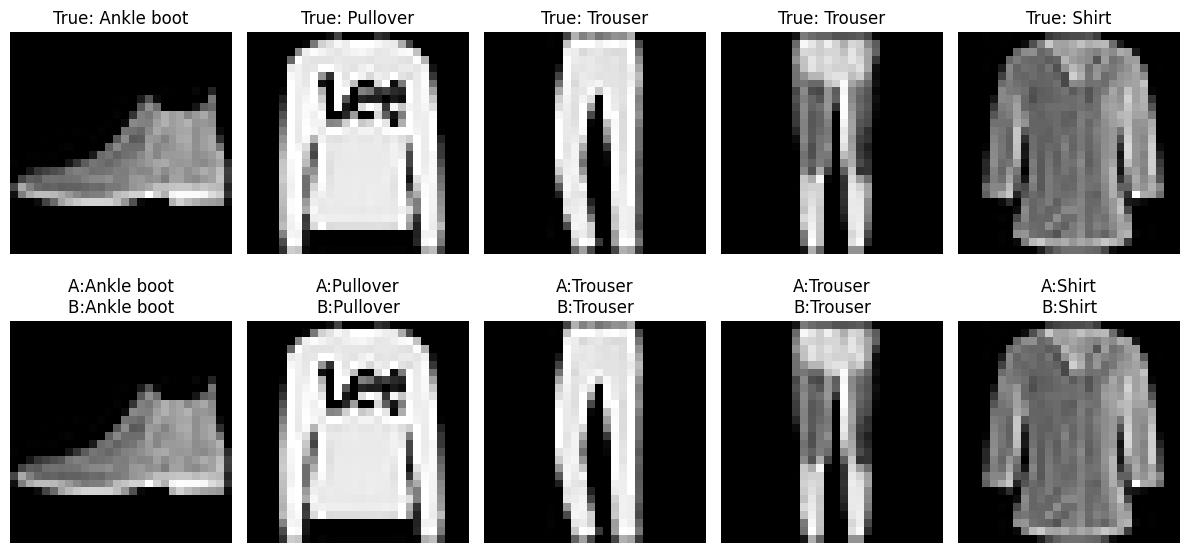

Index 0: True=Ankle boot | Model A=Ankle boot | Model B=Ankle boot
Index 1: True=Pullover | Model A=Pullover | Model B=Pullover
Index 2: True=Trouser | Model A=Trouser | Model B=Trouser
Index 3: True=Trouser | Model A=Trouser | Model B=Trouser
Index 4: True=Shirt | Model A=Shirt | Model B=Shirt


In [5]:
from numpy import argmax

# Choose 5 fixed test indices (reproducible)
indices = [0, 1, 2, 3, 4]

x_samples = x_test[indices]
y_true = y_test[indices]

# Predict with both models
pred_A = model_A.predict(x_samples, verbose=0)
pred_B = model_B.predict(x_samples, verbose=0)

plt.figure(figsize=(12, 6))

for i, idx in enumerate(indices):
    true_label = label_names[int(y_true[i])]

    pred_label_A = label_names[int(argmax(pred_A[i]))]
    pred_label_B = label_names[int(argmax(pred_B[i]))]

    plt.subplot(2, 5, i + 1)
    plt.imshow(x_samples[i], cmap="gray")
    plt.title(f"True: {true_label}")
    plt.axis("off")

    plt.subplot(2, 5, i + 6)
    plt.imshow(x_samples[i], cmap="gray")
    plt.title(f"A:{pred_label_A}\nB:{pred_label_B}")
    plt.axis("off")

plt.tight_layout()
plt.show()

# Print a clean text summary too
for i, idx in enumerate(indices):
    print(f"Index {idx}: True={label_names[int(y_true[i])]} | "
          f"Model A={label_names[int(argmax(pred_A[i]))]} | "
          f"Model B={label_names[int(argmax(pred_B[i]))]}")